In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
from catalog import get_transformed_dataset_splits
from data_config import FEATURES, TARGET
from sklearn.preprocessing import StandardScaler
from models import MixtureDensityNetwork, MDNConfig
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam

import torch

In [7]:
# Load Data
splits = get_transformed_dataset_splits('data/KiDS-DR5-WCScut_x_DESI-DR1-small.fits')
X_train, y_train = splits.train[FEATURES], splits.train[TARGET]

In [8]:
# Scale Training Data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [9]:
# Move train data to DataLoader
X_train_scaled_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

train_dataset = TensorDataset(X_train_scaled_tensor, y_train_tensor)

train_loader = DataLoader(train_dataset, batch_size=256, pin_memory=True, num_workers=16, persistent_workers=True)

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# Training parameters
learning_rate = 1e-4
n_epochs = 100

In [45]:
# Validation data
X_val, y_val = splits.val[FEATURES], splits.val[TARGET]
X_val_scaled = scaler.transform(X_val)

X_val_scaled_tensor = torch.tensor(X_val_scaled).to(device)
y_val_tensor = torch.tensor(y_val).to(device)

# Test data
X_test, y_test = splits.test_faint_complete[FEATURES], splits.test_faint_complete[TARGET]
X_test_scaled = scaler.transform(X_test)

X_test_scaled_tensor = torch.tensor(X_test_scaled).to(device)
y_test_tensor = torch.tensor(y_test).to(device)

In [12]:
# Load Model
model = MixtureDensityNetwork(MDNConfig())
model.to(device)
# Optimizer
optimizer = Adam(model.parameters(), lr=learning_rate)

In [13]:
%%time
# Training Loop
for i in range(n_epochs):
    model.train()   
    epoch_loss = 0.0    
    
    for x, y in train_loader:
        
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)

        dists = model(x)
        batch_loss = -dists.log_prob(y).sum()
        batch_loss.backward()
        optimizer.step()

        epoch_loss += batch_loss.item()

    epoch_loss /= len(train_loader.dataset)

    model.eval()
    nll_test = -model(X_val_scaled_tensor).log_prob(y_val_tensor).mean().item()

    print(f'Epoch {i}, Loss: {epoch_loss}, Val Loss: {nll_test}')

Epoch 0, Loss: 1.1264275253038785, Val Loss: 1.0392239892084372
Epoch 1, Loss: 0.662815943125504, Val Loss: 0.4144677773190739
Epoch 2, Loss: 0.38769371305548267, Val Loss: 0.15727776345270372
Epoch 3, Loss: 0.22267621336002288, Val Loss: 0.047827778045350995
Epoch 4, Loss: 0.0830923207992474, Val Loss: -0.007637676024890478
Epoch 5, Loss: -0.016397383235586382, Val Loss: -0.07361338596173377
Epoch 6, Loss: -0.12632022655855527, Val Loss: -0.17799897083393423
Epoch 7, Loss: -0.20063772582807074, Val Loss: -0.2908009038034659
Epoch 8, Loss: -0.2717530348666537, Val Loss: -0.27092987917711603
Epoch 9, Loss: -0.3183627399172214, Val Loss: -0.3120086531911064
Epoch 10, Loss: -0.3608416824123301, Val Loss: -0.4148424341037609
Epoch 11, Loss: -0.3907522717572213, Val Loss: -0.43887650850920795
Epoch 12, Loss: -0.42333820959590523, Val Loss: -0.44880582266032704
Epoch 13, Loss: -0.4417320247471331, Val Loss: -0.5238300701671593
Epoch 14, Loss: -0.46779687239130124, Val Loss: -0.52501453025624

In [46]:
res = model(X_test_scaled_tensor).sample((5000,)).view(-1).cpu().numpy()

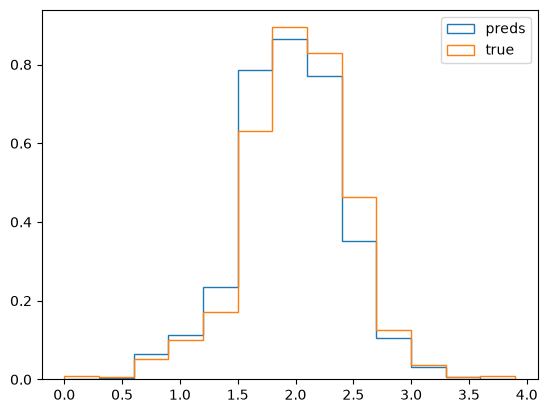

In [47]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(res, bins=np.arange(0,4,0.3), density=True, histtype='step', label='preds')
plt.hist(y_test, bins=np.arange(0,4,0.3), density=True, histtype='step', label='true')
plt.legend()
plt.show()

In [48]:
hist, _ = np.histogram(res, bins=np.arange(0,4,0.3), density=True)
hist_true, _ = np.histogram(y_test, bins=np.arange(0,4,0.3), density=True)

In [49]:
((hist - hist_true)**2).mean() * 1e3

np.float64(3.5150367344503213)